<a href="https://colab.research.google.com/github/simone-cappelletti/ai-sample-projects-library/blob/main/GreenGuard_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Contesto

Negli ultimi mesi le strutture sanitarie hanno subito attacchi sempre più frequenti e sofisticati ma difendere i dati dei pazienti e restare conformi alle normative è essenziale per mantenere la fiducia dei clienti di **GreenGuard**.

# Obiettivo

Capire se agenti addestrati con il Reinforcement Learning possono aiutare a:
- migliorare la difesa, sviluppando strategie di protezione robuste e adattabili in scenari simulati;
- identificare le vulnerabilità delle reti prima che vengano sfruttate da attaccanti reali;
- ottimizzare le risorse, automatizzando la simulazione di attacchi e difese e riducendo il carico di lavoro del team.

# Implementazione

- [gym-idsgame](https://github.com/Kim-Hammar/gym-idsgame): ambiente compatibile con **Gym** pensato per simulare scenari di attacco e difesa in reti informatiche.
- **SARSA**: addestrare un agente con SARSA per affrontare lo scenario di random attack.
- **Double DQN**: implementare con PyTorch un agente Double Deep Q-Network ed applicarlo sia allo scenario di random attack sia a quello di maximal attack.

---

La struttura del notebook prevede:

0. **Preparazione:** installazione **gym-idsgame**, wrapper single-agent, diagnostica dell'ambiente, baseline casuale e funzioni helper.
1. **SARSA** sullo scenario *random attack*.
2. **Double DQN** sugli scenari *random attack* e *maximal attack*.
3. **Confronto finale e conclusioni.**

## Preparazione

Installazione dell'ambiente **gym-idsgame** secondo la seguente [guida](https://colab.research.google.com/drive/15nTl0CSLuSaO_4rQg3eLQXrtfE6qvjYW?usp=sharing):

In [ ]:
!pip install scikit-learn
!pip install --no-deps gym-idsgame

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for gym-idsgame: filename=gym_idsgame-1.0.13-py3-none-any.whl size=969686 sha256=a83a3dec44cf78ab1a06e9cfbd0db1585e69933ccb27ac47e91e59d8f50241eb
  Stored in directory: /root/.cache/pip/wheels/01/d9/e1/a505d26b5a11360285f1052d34b792ae263589fafdad70ba0d
Successfully built gym-idsgame


In [ ]:
import gym_idsgame.envs.util.idsgame_util as _idsgame_util
import gym_idsgame.agents.bot_agents.random_attack_bot_agent as _random_bot
import gym_idsgame.agents.bot_agents.attack_maximal_value_bot_agent as _maximal_bot

if not hasattr(_random_bot, 'idsgame_util'):
  _random_bot.idsgame_util = _idsgame_util
  print("Patch applicata: random_attack_bot_agent")

if not hasattr(_maximal_bot, 'idsgame_util'):
  _maximal_bot.idsgame_util = _idsgame_util
  print("Patch applicata: attack_maximal_value_bot_agent")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Patch applicata: random_attack_bot_agent
Patch applicata: attack_maximal_value_bot_agent


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Definiamo gli ulteriori import e costanti necessarie:

In [ ]:
# Imports
import torch
import torch.nn as nn
import torch.optim as optim
import random
import time
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter, defaultdict, deque
from gym_idsgame.envs import IdsGameRandomAttackV21Env, IdsGameMaximalAttackV21Env

# Costanti
SEED = 42
MAX_STEPS = 100
SCENARI = {
  "random attack": IdsGameRandomAttackV21Env,
  "maximal attack": IdsGameMaximalAttackV21Env,
}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Init
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

Definiamo il `DefenderWrapper` come avviene nella guida.

Come indica la guida stessa questo wrapper trasforma l'ambiente multi-agente in un ambiente single-agent (l'attaccante è già dentro l'ambiente, quindi si addestra solo il difensore) compatibile con qualsiasi algoritmo RL standard (SARSA, Q-Learning, DQN, DDQN...).

In [ ]:
class DefenderWrapper:
  """
  Wrapper che adatta gym-idsgame per il single-agent (difensore).
  L'attaccante è gestito dal bot interno dell'ambiente.

  Parametri:
  - env: ambiente gym-idsgame già istanziato.
  - max_steps: numero massimo di passi per episodio (oltre la quale avviene il troncamento).
  - reward_mode: "env" = reward originale del difensore,
                 "outcome" = +1 rilevato, -1 hackerato, 0 altrimenti.
  """
  def __init__(self, env, max_steps=MAX_STEPS, reward_mode="outcome"):
    self.env = env
    self.max_steps = max_steps
    self.reward_mode = reward_mode
    self.action_space = env.defender_action_space
    self.n_actions = env.defender_action_space.n
    self.steps = 0

  def reset(self):
    obs = self.env.reset() # reset() restituisce (attacker_obs, defender_obs)
    if isinstance(obs, tuple):
      obs = obs[1]
    self.steps = 0
    return obs.flatten()

  def step(self, action):
    # Passiamo un'azione qualsiasi (!= -1) per attivare il bot attaccante
    attacker_action = self.env.attacker_action_space.sample()
    res = self.env.step((attacker_action, action))

    obs, reward, done = res[0], res[1], res[2]
    info = dict(res[3]) if len(res) > 3 and isinstance(res[3], dict) else {}

    # Estraiamo solo la parte del difensore
    if isinstance(obs, tuple):
      obs = obs[1]
    if isinstance(reward, tuple):
      reward = reward[1]

    self.steps += 1
    terminated = bool(done)
    truncated = (not terminated) and self.steps >= self.max_steps

    # Esito dell'episodio
    outcome = None
    if terminated:
      if self.env.state.detected:
        outcome = "detected"
      elif self.env.state.hacked:
        outcome = "hacked"
      else:
        outcome = "unknown"
    elif truncated:
      outcome = "timeout"
    info["outcome"] = outcome

    if self.reward_mode == "outcome":
      reward = {"detected": 1.0, "hacked": -1.0}.get(outcome, 0.0)

    return obs.flatten(), float(reward), terminated, truncated, info

Alcune modifiche effettuate rispetto alla guida:
- `info["outcome"]`: a fine episodio può valere `detected` (attaccante rilevato), `hacked` (dati raggiunti/hackerati) o `timeout`. Viene letto da `env.state.detected`/`env.state.hacked`. Questo perché la reward originale non dice in modo esplicito come è finito l'episodio ma l'esito ci serve per misurare il *win rate* e per costruire la reward.
- `max_steps`: limita la lunghezza dell'episodio al fine di evitare episodi troppo lunghi. Il timeout è un **troncamento** e non uno stato terminale quindi l'aggiornamento degli agenti deve continuare a fare bootstrap sul valore dello stato successivo.
- `reward_mode`: `"env"` restituisce il reward originale, `"outcome"` restituisce **+1** se l'attaccante è rilevato, **−1** se raggiunge i dati, **0** altrimenti.
- `step()`: restituisce 5 valori, `(obs, reward, terminated, truncated, info)` invece dei 4 presenti della guida. In questo modo la distinzione tra fine naturale e timeout è chiara ed esplicita.

Ora prima di addestrare qualsiasi agente ispezioniamo l'ambiente. Necessitiamo di:
1. **Formato dei dati:** dimensione e range dell'osservazione e numero di azioni del difensore. Servono per il dimensionamento della Q-table e della rete, e per la normalizzazione degli input del DDQN.
2. **Reward originale per esito:** con un difensore casuale e `reward_mode="env"`, guardiamo quanto vale la reward cumulata originale negli episodi vinti (`detected`), persi (`hacked`) o andati in timeout. Questo serve a motivare la scelta della reward.
3. **Durata naturale degli episodi:** serve a scegliere un valore sensato per `MAX_STEPS`.

In [ ]:
# Formato dei dati e qualche passo di prova
for nome, env_cls in SCENARI.items():
  env = DefenderWrapper(env_cls(), reward_mode="env")
  obs = env.reset()
  print(f"=== {nome} ===")
  print(f"env.state ha 'detected': {hasattr(env.env.state, 'detected')}, "
        f"'hacked': {hasattr(env.env.state, 'hacked')}")
  print(f"Osservazione: shape={obs.shape}, dtype={obs.dtype}, min={obs.min()}, max={obs.max()}")
  print(f"Numero azioni difensore: {env.n_actions}")
  for i in range(5): # 5 passi casuali
    obs, r, term, trunc, info = env.step(env.action_space.sample())
    print(f"  passo {i+1}: reward={r:.3f}, terminated={term}, truncated={trunc}, "
          f"outcome={info['outcome']}")
    if term or trunc:
      break
  print()

=== random attack ===
env.state ha 'detected': True, 'hacked': True
Osservazione: shape=(20,), dtype=float64, min=0.0, max=1.0
Numero azioni difensore: 20
  passo 1: reward=0.000, terminated=False, truncated=False, outcome=None
  passo 2: reward=0.000, terminated=True, truncated=False, outcome=detected

=== maximal attack ===
env.state ha 'detected': True, 'hacked': True
Osservazione: shape=(20,), dtype=float64, min=0.0, max=1.0
Numero azioni difensore: 20
  passo 1: reward=0.000, terminated=True, truncated=False, outcome=detected



=== random attack: 300 episodi, difensore casuale, reward originale ===
Range osservato delle osservazioni: [0.0, 5.0]
esito       episodi  reward medio      min      max  lunghezza media
detected        153         0.013    0.000    1.000              3.9
hacked          147       -25.993  -26.000  -25.000              5.9

=== maximal attack: 300 episodi, difensore casuale, reward originale ===
Range osservato delle osservazioni: [0.0, 4.0]
esito       episodi  reward medio      min      max  lunghezza media
detected        110         0.000    0.000    0.000              2.8
hacked          190       -25.995  -26.000  -25.000              4.6



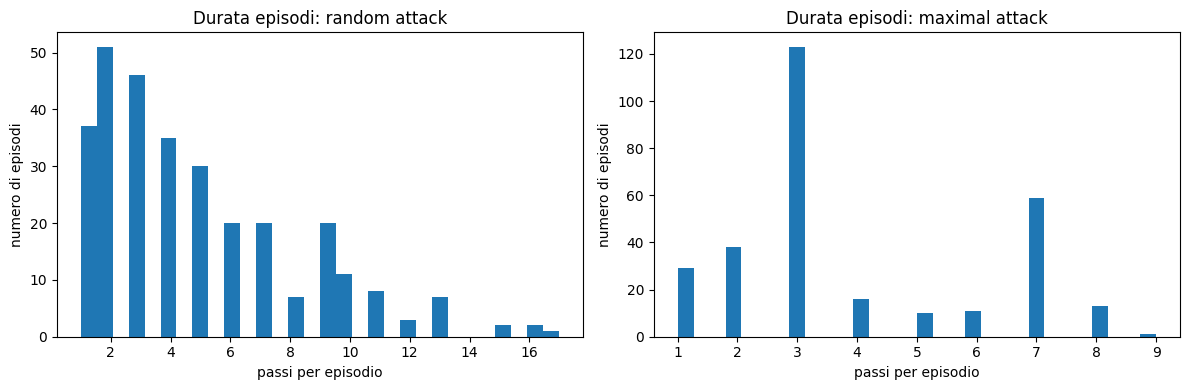

In [ ]:
# Reward originale per esito e durata degli episodi (difensore casuale)
N_DIAG = 300
diag_lunghezze = {}

for nome, env_cls in SCENARI.items():
  env = DefenderWrapper(env_cls(), reward_mode="env")
  per_esito = defaultdict(lambda: {"reward": [], "lunghezza": []})
  oss_min, oss_max = np.inf, -np.inf

  for _ in range(N_DIAG):
    obs = env.reset()
    ep_reward, done = 0.0, False
    while not done:
      obs, r, term, trunc, info = env.step(env.action_space.sample())
      ep_reward += r
      oss_min, oss_max = min(oss_min, obs.min()), max(oss_max, obs.max())
      done = term or trunc
    per_esito[info["outcome"]]["reward"].append(ep_reward)
    per_esito[info["outcome"]]["lunghezza"].append(env.steps)

  diag_lunghezze[nome] = [l for d in per_esito.values() for l in d["lunghezza"]]

  print(f"=== {nome}: {N_DIAG} episodi, difensore casuale, reward originale ===")
  print(f"Range osservato delle osservazioni: [{oss_min}, {oss_max}]")
  print(f"{'esito':<10}{'episodi':>9}{'reward medio':>14}{'min':>9}{'max':>9}{'lunghezza media':>17}")
  for esito, d in sorted(per_esito.items()):
    r = np.array(d["reward"])
    print(f"{esito:<10}{len(r):>9}{r.mean():>14.3f}{r.min():>9.3f}{r.max():>9.3f}"
          f"{np.mean(d['lunghezza']):>17.1f}")
  print()

fig, axes = plt.subplots(1, len(diag_lunghezze), figsize=(12, 4))
for ax, (nome, lunghezze) in zip(axes, diag_lunghezze.items()):
  ax.hist(lunghezze, bins=30)
  ax.set_title(f"Durata episodi: {nome}")
  ax.set_xlabel("passi per episodio")
  ax.set_ylabel("numero di episodi")
plt.tight_layout()
plt.show()

Notiamo che:
- **Dati:** in entrambi gli scenari l'osservazione del difensore è un vettore di **20 valori** e il difensore ha **20 azioni**. All'inizio dell'episodio i valori sono compresi tra 0 e 1, mentre durante gli episodi casuali arrivano fino a 5 nel random attack e fino a 4 nel maximal attack.
- **Reward originale per esito:** quando l'attaccante raggiunge i dati la reward cumulata è circa **-26**, quando viene rilevato è quasi sempre **0** (media 0.013 nel random attack e sempre 0 nel maximal attack). La reward originale distingue quindi gli esiti, il problema è che:
  - la vittoria non dà in pratica nessun segnale positivo: rilevare l'attaccante vale quasi sempre 0, come un timeout;
  - la scala è molto asimmetrica (-26 contro 0). Per il DDQN, che ha un output lineare e una loss quadratica, target di questa ampiezza rendono l'addestramento meno stabile.

  Per questo usiamo `reward_mode="outcome"` con **+1** se l'attaccante è rilevato, **-1** se raggiunge i dati e **0** altrimenti.
- **Esiti:** nei 600 episodi gli esiti sono solo `detected` o `hacked` quindi non compaiono né `unknown` né `timeout`.
- **Durata:** gli episodi sono brevi, al massimo **17 passi** nel random attack e **9** nel maximal attack, con durata media di 4-5 passi. Fissiamo quindi `MAX_STEPS = 100` (usato anche nella guida) che è più di 5 volte la durata massima osservata, quindi non taglia gli episodi normali ma al tempo stesso fa da limite se un agente addestrato riuscisse a prolungare molto la partita.

Definiamo ora alcune funzioni helpers:
- `moving_average`: media mobile per rendere leggibili le curve di training;
- `plot_training`: disegna più curve di training affiancate, con la serie grezza in trasparenza e la media mobile sopra;
- `evaluate_policy`: esegue una policy fissata per `n_episodes` e restituisce la percentuale di episodi `detected`/`hacked`/`timeout`, la reward media e la durata media. Per gli agenti useremo la policy **greedy** (ε = 0), così valutiamo ciò che hanno imparato senza il rumore dell'esplorazione.

In [ ]:
def moving_average(data, window_size):
  """
  Media mobile semplice.
  """
  data = np.asarray(data, dtype=float)
  if len(data) < window_size:
    return np.array([])
  return np.convolve(data, np.ones(window_size) / window_size, mode="valid")


def plot_training(curves, window=100, title=None):
  """
  Disegna una o più curve di training affiancate.
  """
  fig, axes = plt.subplots(1, len(curves), figsize=(5 * len(curves), 4), squeeze=False)
  for ax, (nome, valori) in zip(axes[0], curves.items()):
    ax.plot(valori, alpha=0.3, label="grezzo")
    ma = moving_average(valori, window)
    if len(ma) > 0:
      ax.plot(np.arange(window - 1, len(valori)), ma, label=f"media mobile ({window})")
    ax.set_title(nome)
    ax.set_xlabel("episodio")
    ax.legend()
  if title:
    fig.suptitle(title)
  plt.tight_layout()
  plt.show()


def evaluate_policy(env, policy_fn, n_episodes=500):
  """
  Valuta una policy fissata. policy_fn(obs) -> azione.
  Restituisce le frequenze degli esiti, il reward medio (con dev. std.) e la durata media.
  """
  esiti, rewards, lunghezze = Counter(), [], []
  for _ in range(n_episodes):
    obs = env.reset()
    ep_reward, done = 0.0, False
    while not done:
      obs, r, term, trunc, info = env.step(policy_fn(obs))
      ep_reward += r
      done = term or trunc
    esiti[info["outcome"]] += 1
    rewards.append(ep_reward)
    lunghezze.append(env.steps)
  return {
    "detected": esiti["detected"] / n_episodes,
    "hacked": esiti["hacked"] / n_episodes,
    "timeout": esiti["timeout"] / n_episodes,
    "unknown": esiti["unknown"] / n_episodes,
    "reward_mean": float(np.mean(rewards)),
    "reward_std": float(np.std(rewards)),
    "length_mean": float(np.mean(lunghezze))
  }


def print_eval(nome, res):
  """
  Stampa compatta del risultato di evaluate_policy.
  """
  print(f"{nome:<32} detected={res['detected']:6.1%}  hacked={res['hacked']:6.1%}  "
        f"timeout={res['timeout']:6.1%}  reward={res['reward_mean']:+.3f} ± {res['reward_std']:.3f}  "
        f"durata media={res['length_mean']:.1f}")

Ora prima di addestrare gli agenti misuriamo quanto ottiene un difensore che sceglie **a caso**, in entrambi gli scenari e con la stessa reward e la stessa funzione di valutazione che useremo per SARSA e DDQN.

Sarà il nostro punto di riferimento perché un agente che ha imparato qualcosa dovrà sicuramente fare meglio di così.

I risultati vengono salvati nel dizionario `results`, da usare alla fine del notebook per il grafico di confronto.

In [ ]:
N_EVAL = 2_000
results = {}

for nome, env_cls in SCENARI.items():
  env = DefenderWrapper(env_cls(), reward_mode="outcome")
  res = evaluate_policy(env, lambda obs: env.action_space.sample(), n_episodes=N_EVAL)
  results[("Baseline casuale", nome)] = res
  print_eval(f"Baseline casuale - {nome}", res)

Baseline casuale - random attack detected= 48.9%  hacked= 51.1%  timeout=  0.0%  reward=-0.023 ± 1.000  durata media=5.0
Baseline casuale - maximal attack detected= 35.1%  hacked= 64.8%  timeout=  0.0%  reward=-0.297 ± 0.955  durata media=4.1


Notiamo che:
- nel **random attack** il difensore casuale vince praticamente un episodio su due: 48.9% `detected` contro 51.1% `hacked`, con reward media di -0.023;
- nel **maximal attack** perde più spesso: 35.1% `detected` contro 64.8% `hacked`, con reward media di -0.297;
- non ci sono timeout infatti la durata media è di 5 e 4.1 passi.

Questi saranno i valori da battere.

## SARSA

Come richiesto applichiamo SARSA allo scenario *random attack*, in cui l'attaccante sceglie le mosse in maniera casuale.

Iperparametri:

| Iperparametro | Valore | Motivazione |
|---|---|---|
| Episodi | 30.000 | Con episodi di circa 5 passi (come nella baseline) sono circa 150.000 aggiornamenti, abbastanza per stimare bene le Q degli stati visitati più spesso in tempi ragionevoli. |
| α (learning rate) | 0.1 | L'attaccante sceglie a caso, quindi la stessa coppia (s, a) può finire con +1 o con −1 e un α piccolo fa una media dei target invece di inseguire l'ultimo esito. |
| γ (discount) | 0.99 | La reward arriva solo a fine episodio e gli episodi sono brevi: con γ vicino a 1, Q(s, a) stima in pratica P(detected) − P(hacked) a partire da (s, a). |
| ε iniziale → finale | 1.0 → 0.05 | All'inizio la Q-table è vuota e conviene esplorare tutto. SARSA è on-policy, cioè impara il valore della policy ε-greedy che segue, un ε finale piccolo rende le Q vicine a quelle della policy greedy che valutiamo alla fine. |
| Decadimento di ε | lineare nei primi 15.000 episodi, poi fisso | Metà training per esplorare e metà per consolidare la policy. |
| Reward | `"outcome"` | Come anticipato +1 se l'attaccante è rilevato, −1 se raggiunge i dati, 0 altrimenti. |
| `MAX_STEPS` | 100 | Come nella Preparazione. |

In [ ]:
def choose_action(Q, state, epsilon, n_actions):
  """
  Politica ε-greedy con tie-breaking casuale.
  Con probabilità ε sceglie un'azione a caso, altrimenti una delle azioni con Q massimo.
  """
  if np.random.rand() < epsilon:
    return np.random.randint(n_actions)
  q = Q[state]
  return int(np.random.choice(np.flatnonzero(q == q.max())))


def sarsa(env, episodes, alpha, gamma, eps_start, eps_end, eps_decay_episodes, log_every=5000):
  """
  Addestra un agente SARSA tabellare.
  Restituisce la Q-table e la storia del training (una voce per episodio).
  """
  Q = defaultdict(lambda: np.zeros(env.n_actions))
  storia = {"reward": [], "detected": [], "epsilon": [], "stati": []}

  for episode in range(episodes):
    # ε decresce linearmente fino a eps_end, poi resta fisso
    epsilon = max(eps_end, eps_start - (eps_start - eps_end) * episode / eps_decay_episodes)

    state = tuple(env.reset())
    action = choose_action(Q, state, epsilon, env.n_actions)
    ep_reward, done = 0.0, False

    while not done:
      next_obs, reward, terminated, truncated, info = env.step(action)
      next_state = tuple(next_obs)

      if terminated:
        # Stato terminale: nessun valore futuro, niente bootstrap
        td_target = reward
      else:
        # Anche in caso di troncatura (timeout) facciamo bootstrap
        next_action = choose_action(Q, next_state, epsilon, env.n_actions)
        td_target = reward + gamma * Q[next_state][next_action]

      td_error = td_target - Q[state][action]
      Q[state][action] += alpha * td_error

      ep_reward += reward
      done = terminated or truncated
      if not done:
        state, action = next_state, next_action

    storia["reward"].append(ep_reward)
    storia["detected"].append(1.0 if info["outcome"] == "detected" else 0.0)
    storia["epsilon"].append(epsilon)
    storia["stati"].append(len(Q))

    if (episode + 1) % log_every == 0:
      win_rate = np.mean(storia["detected"][-log_every:])
      print(f"Episodio {episode + 1:6d}  ε={epsilon:.3f}  "
            f"win rate ultimi {log_every}={win_rate:.1%}  stati visitati={len(Q)}")

  return Q, storia

Addestriamo l'agente con gli iperparametri scelti della tabella:

In [ ]:
# Iperparametri
EPISODI_SARSA = 30000
ALPHA = 0.1
GAMMA = 0.99
EPS_START, EPS_END = 1.0, 0.05
EPS_DECAY_EPISODI = EPISODI_SARSA // 2

In [ ]:
# Reimpostiamo i seed prima del training
random.seed(SEED)
np.random.seed(SEED)

env_sarsa = DefenderWrapper(IdsGameRandomAttackV21Env(), reward_mode="outcome")
inizio = time.time()
Q_sarsa, storia_sarsa = sarsa(env_sarsa, EPISODI_SARSA, ALPHA, GAMMA,
                              EPS_START, EPS_END, EPS_DECAY_EPISODI)
print(f"\nTraining completato in {time.time() - inizio:.0f} s, stati nella Q-table: {len(Q_sarsa)}")

Episodio   5000  ε=0.683  win rate ultimi 5000=49.8%  stati visitati=9981
Episodio  10000  ε=0.367  win rate ultimi 5000=50.2%  stati visitati=17820
Episodio  15000  ε=0.050  win rate ultimi 5000=53.0%  stati visitati=24331
Episodio  20000  ε=0.050  win rate ultimi 5000=56.6%  stati visitati=30079
Episodio  25000  ε=0.050  win rate ultimi 5000=58.0%  stati visitati=34935
Episodio  30000  ε=0.050  win rate ultimi 5000=54.8%  stati visitati=40398

Training completato in 119 s, stati nella Q-table: 40398


Vediamo l'andamento del training: reward e win rate per episodio (con media mobile su 500 episodi), valore di ε e numero di stati nella Q-table.

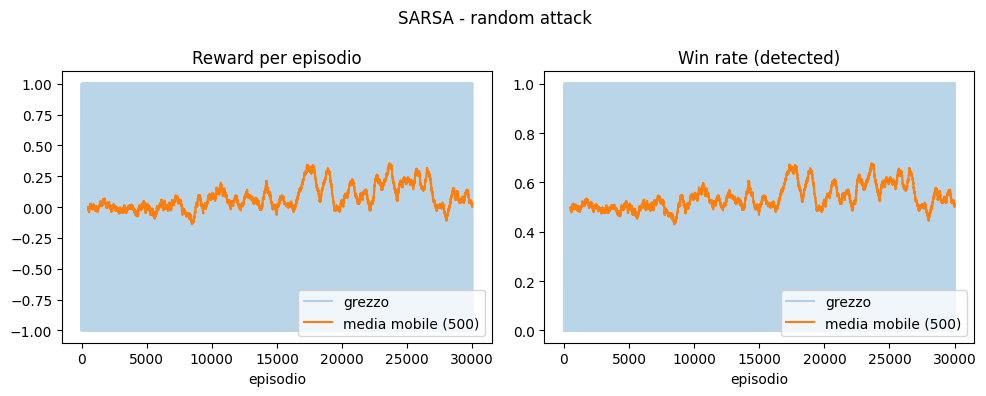

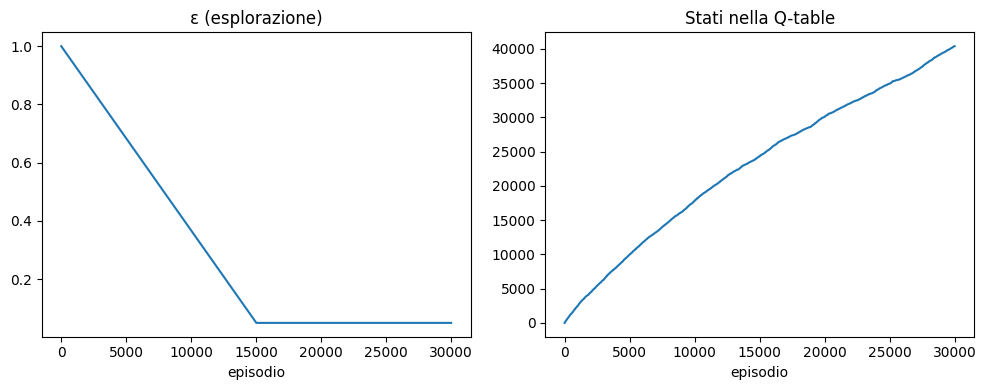

In [ ]:
plot_training({
  "Reward per episodio": storia_sarsa["reward"],
  "Win rate (detected)": storia_sarsa["detected"],
}, window=500, title="SARSA - random attack")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(storia_sarsa["epsilon"])
axes[0].set_title("ε (esplorazione)")
axes[0].set_xlabel("episodio")
axes[1].plot(storia_sarsa["stati"])
axes[1].set_title("Stati nella Q-table")
axes[1].set_xlabel("episodio")
plt.tight_layout()
plt.show()

Notiamo che:
- **Prima metà (ε da 1 a 0.05):** nei primi 10.000 episodi il win rate resta intorno al 50% come la baseline casuale, perché con ε alto l'agente gioca quasi a caso. Sale al 53.0% poi nel blocco successivo, mentre ε scende verso 0.05.
- **Seconda metà (ε = 0.05):** il win rate sale al 56.6% e al 58.0%, poi torna al 54.8% negli ultimi 5.000 episodi. La media mobile non si stabilizza ma oscilla tra circa 0.45 e 0.65.
- **Reward:** gli episodi finiscono solo con +1 o -1, quindi la reward media vale 2 × win rate - 1 e i due grafici hanno la stessa forma.
- **Stati:** la Q-table arriva a **40.398 stati** e cresce quasi linearmente fino alla fine, anche dopo che ε si è fermato a 0.05.

Valutiamo infine la policy **greedy** (ε = 0) con la stessa funzione `evaluate_policy` e lo stesso numero di episodi (`N_EVAL`) della baseline. Durante la valutazione contiamo anche:
- quanti passi cadono in stati **mai visti** in training: lì tutte le Q valgono 0 e la scelta è casuale;
- quali azioni la policy sceglie più spesso, cioè quale strategia di difesa ha imparato.

In [ ]:
# Policy greedy (ε = 0) che non modifica la Q-table
conteggi = Counter()
azioni_greedy = Counter()

def policy_sarsa(obs):
  state = tuple(obs)
  conteggi["passi"] += 1
  if state not in Q_sarsa:
    # Stato mai visto: tutte le Q valgono 0, scelta casuale
    conteggi["stati mai visti"] += 1
    azione = np.random.randint(env_sarsa.n_actions)
  else:
    azione = choose_action(Q_sarsa, state, 0.0, env_sarsa.n_actions)
  azioni_greedy[azione] += 1
  return azione

res = evaluate_policy(env_sarsa, policy_sarsa, n_episodes=N_EVAL)
results[("SARSA", "random attack")] = res

print_eval("Baseline casuale - random attack", results[("Baseline casuale", "random attack")])
print_eval("SARSA greedy - random attack", res)

quota = conteggi["stati mai visti"] / conteggi["passi"]
print(f"\nPassi in stati mai visti in training: {conteggi['stati mai visti']}/{conteggi['passi']} ({quota:.1%})")

print("\nAzioni più scelte dalla policy greedy (nodo = azione // 5, tipo = azione % 5, 4 = rilevamento):")
for azione, n in azioni_greedy.most_common(5):
  print(f"  azione {azione:2d} (nodo {azione // 5}, tipo {azione % 5}): {n / conteggi['passi']:.1%}")

Baseline casuale - random attack detected= 48.9%  hacked= 51.1%  timeout=  0.0%  reward=-0.023 ± 1.000  durata media=5.0
SARSA greedy - random attack     detected= 60.2%  hacked= 39.9%  timeout=  0.0%  reward=+0.203 ± 0.979  durata media=4.6

Passi in stati mai visti in training: 1962/9171 (21.4%)

Azioni più scelte dalla policy greedy (nodo = azione // 5, tipo = azione % 5, 4 = rilevamento):
  azione  4 (nodo 0, tipo 4): 24.9%
  azione 15 (nodo 3, tipo 0): 21.9%
  azione 18 (nodo 3, tipo 3): 16.7%
  azione  1 (nodo 0, tipo 1): 3.1%
  azione  5 (nodo 1, tipo 0): 2.5%


Notiamo che:
- **Confronto con la baseline:** la policy greedy rileva l'attaccante nel **60.2%** degli episodi contro il 48.9% della baseline casuale.
- **Strategia appresa:** l'azione più usata è la **4**, rilevamento sul nodo dati.
- **Limiti impliciti del metodo tabellare:** ogni stato viene imparato da solo, senza generalizzare. Due stati che differiscono solo per una difesa sullo START sono per il gioco la stessa situazione, ma per la Q-table sono righe diverse.

## Double DQN

Come richiesto applichiamo ora un agente **Double DQN**, prima allo scenario *random attack* e poi al *maximal attack*.

Con SARSA abbiamo visto i limiti dell'approccio tabellare infatti la Q-table supera i 40.000 stati e cresce ancora a fine training. Un **Deep Q-Network** sostituisce la tabella con una rete neurale che riceve l'osservazione e restituisce un valore Q per ciascuna delle 20 azioni quindi stati simili producono stime simili, anche se uno dei due non è mai stato visitato.

Iperparametri (uguali per i due scenari):

| Iperparametro | Valore | Motivazione |
|---|---|---|
| Episodi | 30.000 | Gli stessi di SARSA. |
| Rete | 20 → 512 → 20, ReLU sullo strato nascosto, output lineare | L'output è lineare perché le Q stimano in pratica P(detected) − P(hacked) e possono essere negative. |
| Input | osservazione / 9 | 9 è il valore massimo di difesa e rilevamento. |
| Ottimizzatore | Adam (learning rate 3·10⁻⁴) |  |
| Loss | errore quadratico medio (MSE) |  |
| Batch | 64 |  |
| Replay buffer | 100.000 transizioni | Con episodi di circa 5 passi (baseline) contiene circa gli ultimi 20.000 episodi. |
| Target net | copia dei pesi ogni 1.000 passi di gradiente |  |
| γ (discount) | 0.99 | Come SARSA. |
| ε iniziale → finale | 1.0 → 0.05 | Come SARSA, così le curve di training sono confrontabili. |
| Decadimento di ε | lineare per passo in 75.000 passi, poi fisso | Con episodi di circa 5 passi corrisponde alla prima metà del training, come in SARSA. |
| Reward | `"outcome"` | +1 se l'attaccante è rilevato, −1 se raggiunge i dati, 0 altrimenti. |
| Device | GPU se disponibile |  |

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cpu


In [ ]:
class QNetwork(nn.Module):
  """
  Rete Q: osservazione normalizzata -> un valore Q per ogni azione.
  Come nel corso uno strato nascosto da 512 neuroni, ma con output lineare.
  """
  def __init__(self, n_inputs, n_actions, hidden=512):
    super().__init__()
    self.fc1 = nn.Linear(n_inputs, hidden)
    self.fc2 = nn.Linear(hidden, n_actions)

  def forward(self, x):
    x = torch.relu(self.fc1(x))
    # Nessuna ReLU sull'output: le Q possono essere negative
    return self.fc2(x)


class ReplayBuffer:
  """
  Memoria delle transizioni, come nel corso: un deque a capacità fissa da cui estrarre batch casuali.
  """
  def __init__(self, capacity):
    self.buffer = deque(maxlen=capacity)

  def push(self, state, action, reward, next_state, done):
    self.buffer.append((state, action, reward, next_state, done))

  def sample(self, batch_size):
    state, action, reward, next_state, done = zip(*random.sample(self.buffer, batch_size))
    return (np.array(state), np.array(action), np.array(reward),
            np.array(next_state), np.array(done))

  def __len__(self):
    return len(self.buffer)


class DDQNAgent:
  """
  Agente Double DQN: policy net, target net, ottimizzatore e replay buffer.
  """
  def __init__(self, n_inputs, n_actions, obs_scale, lr, gamma, batch_size, memory_size, target_update):
    self.n_actions = n_actions
    self.obs_scale = obs_scale
    self.gamma = gamma
    self.batch_size = batch_size
    self.target_update = target_update

    self.policy_net = QNetwork(n_inputs, n_actions).to(DEVICE)
    self.target_net = QNetwork(n_inputs, n_actions).to(DEVICE)
    self.target_net.load_state_dict(self.policy_net.state_dict())
    self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
    self.memory = ReplayBuffer(memory_size)
    self.n_updates = 0

  def normalize(self, obs):
    """
    Porta l'osservazione in [0, 1] dividendo per il valore massimo dell'ambiente.
    """
    return np.asarray(obs, dtype=np.float32) / self.obs_scale

  def select_action(self, obs, epsilon):
    """
    Politica ε-greedy: con probabilità ε un'azione a caso, altrimenti quella con Q massimo.
    """
    if random.random() < epsilon:
      return random.randrange(self.n_actions)
    with torch.no_grad():
      state = torch.as_tensor(self.normalize(obs), device=DEVICE).unsqueeze(0)
      return int(self.policy_net(state).argmax(1).item())

  def optimize(self):
    """
    Un passo di gradiente su un batch estratto dal buffer.
    Restituisce la loss, oppure None se il buffer non contiene ancora un batch.
    """
    if len(self.memory) < self.batch_size:
      return None
    state, action, reward, next_state, terminated = self.memory.sample(self.batch_size)

    state = torch.as_tensor(state, device=DEVICE)
    action = torch.as_tensor(action, dtype=torch.long, device=DEVICE)
    reward = torch.as_tensor(reward, dtype=torch.float32, device=DEVICE)
    next_state = torch.as_tensor(next_state, device=DEVICE)
    terminated = torch.as_tensor(terminated, dtype=torch.float32, device=DEVICE)

    # Q(s, a) della policy net per le azioni effettivamente eseguite
    q_value = self.policy_net(state).gather(1, action.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
      # Double DQN: la policy net sceglie l'azione successiva, la target net la valuta
      next_action = self.policy_net(next_state).argmax(1, keepdim=True)
      next_q_value = self.target_net(next_state).gather(1, next_action).squeeze(1)
      # Niente bootstrap se l'episodio è terminato (ma sì in caso di troncatura)
      target = reward + self.gamma * next_q_value * (1 - terminated)

    loss = (q_value - target).pow(2).mean()

    self.optimizer.zero_grad()
    loss.backward()
    self.optimizer.step()

    # Sincronizzazione periodica della target net
    self.n_updates += 1
    if self.n_updates % self.target_update == 0:
      self.target_net.load_state_dict(self.policy_net.state_dict())

    return loss.item()

In [ ]:
def train_ddqn(env_cls, episodes, lr, gamma, batch_size, memory_size, target_update,
               eps_start, eps_end, eps_decay_steps, log_every=5000):
  """
  Addestra un agente Double DQN sullo scenario env_cls.
  Restituisce l'agente, l'ambiente e la storia del training (una voce per episodio).
  """
  # Reimpostiamo i seed: ogni scenario parte dalle stesse condizioni
  random.seed(SEED)
  np.random.seed(SEED)
  torch.manual_seed(SEED)

  env = DefenderWrapper(env_cls(), reward_mode="outcome")
  n_inputs = len(env.reset())
  max_value = env.env.idsgame_config.game_config.max_value
  agent = DDQNAgent(n_inputs, env.n_actions, max_value, lr, gamma,
                    batch_size, memory_size, target_update)
  storia = {"reward": [], "detected": [], "epsilon": [], "loss": []}
  passi = 0

  for episode in range(episodes):
    obs = env.reset()
    ep_reward, ep_loss, done = 0.0, [], False

    while not done:
      # ε decresce linearmente a ogni passo fino a eps_end, poi resta fisso
      epsilon = max(eps_end, eps_start - (eps_start - eps_end) * passi / eps_decay_steps)
      action = agent.select_action(obs, epsilon)
      next_obs, reward, terminated, truncated, info = env.step(action)

      # Nel buffer salviamo gli stati già normalizzati e solo terminated (non la troncatura)
      agent.memory.push(agent.normalize(obs), action, reward,
                        agent.normalize(next_obs), float(terminated))
      loss = agent.optimize()
      if loss is not None:
        ep_loss.append(loss)

      obs = next_obs
      ep_reward += reward
      passi += 1
      done = terminated or truncated

    storia["reward"].append(ep_reward)
    storia["detected"].append(1.0 if info["outcome"] == "detected" else 0.0)
    storia["epsilon"].append(epsilon)
    storia["loss"].append(np.mean(ep_loss) if ep_loss else np.nan)

    if (episode + 1) % log_every == 0:
      win_rate = np.mean(storia["detected"][-log_every:])
      print(f"Episodio {episode + 1:6d}  ε={epsilon:.3f}  "
            f"win rate ultimi {log_every}={win_rate:.1%}  passi totali={passi}")

  print(f"max_value usato per la normalizzazione: {max_value}")
  return agent, env, storia

### Random attack

Addestriamo l'agente sullo scenario random attack con gli iperparametri della tabella:

In [ ]:
# Iperparametri, uguali per i due scenari
EPISODI_DDQN = 30000
HP_DDQN = dict(
  lr=3e-4,
  gamma=0.99,
  batch_size=64,
  memory_size=100000,
  target_update=1000,
  eps_start=1.0,
  eps_end=0.05,
  eps_decay_steps=75000
)

inizio = time.time()
agent_ddqn_random, env_ddqn_random, storia_ddqn_random = train_ddqn(
  IdsGameRandomAttackV21Env, EPISODI_DDQN, **HP_DDQN)
print(f"\nTraining completato in {time.time() - inizio:.0f} s")

Episodio   5000  ε=0.684  win rate ultimi 5000=52.3%  passi totali=24922


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Episodio  10000  ε=0.373  win rate ultimi 5000=56.1%  passi totali=49488
Episodio  15000  ε=0.080  win rate ultimi 5000=63.8%  passi totali=72619
Episodio  20000  ε=0.050  win rate ultimi 5000=64.3%  passi totali=95231
Episodio  25000  ε=0.050  win rate ultimi 5000=66.8%  passi totali=117452
Episodio  30000  ε=0.050  win rate ultimi 5000=70.9%  passi totali=138746
max_value usato per la normalizzazione: 9

Training completato in 490 s


Vediamo l'andamento del training: reward, win rate e loss media per episodio (con media mobile su 500 episodi), poi il valore di ε e il win rate di SARSA e Double DQN a confronto, a parità di episodi.

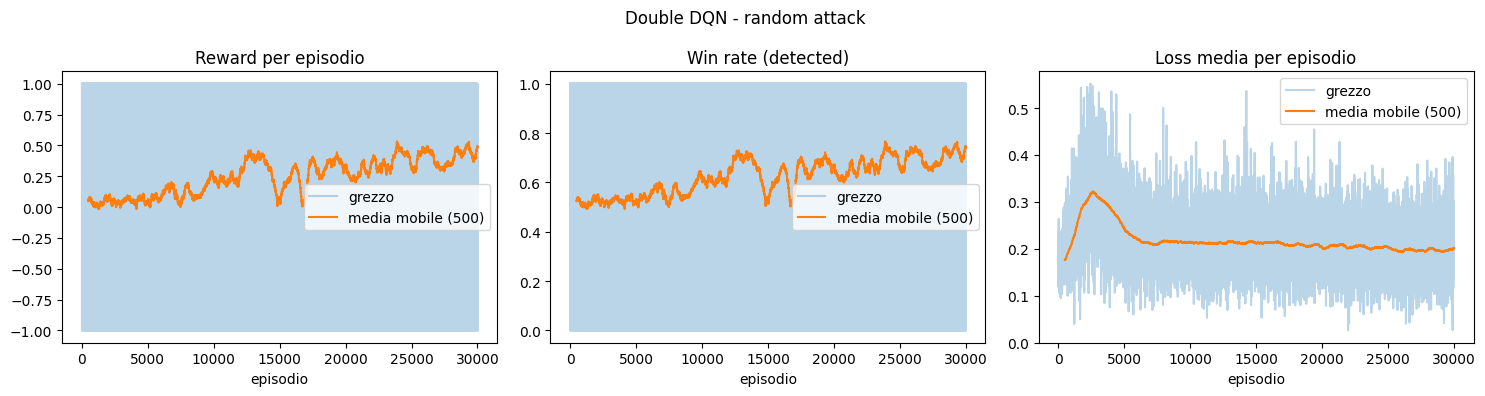

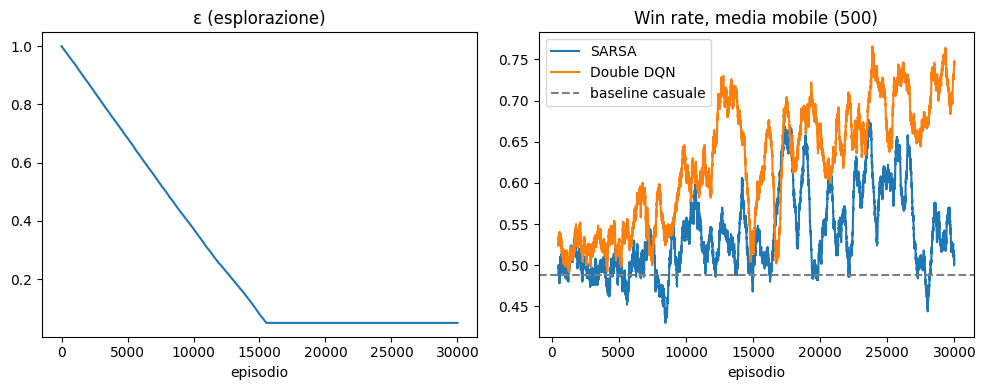

In [ ]:
plot_training({
  "Reward per episodio": storia_ddqn_random["reward"],
  "Win rate (detected)": storia_ddqn_random["detected"],
  "Loss media per episodio": storia_ddqn_random["loss"],
}, window=500, title="Double DQN - random attack")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(storia_ddqn_random["epsilon"])
axes[0].set_title("ε (esplorazione)")
axes[0].set_xlabel("episodio")
for nome, storia in [("SARSA", storia_sarsa), ("Double DQN", storia_ddqn_random)]:
  ma = moving_average(storia["detected"], 500)
  axes[1].plot(np.arange(499, len(storia["detected"])), ma, label=nome)
axes[1].axhline(results[("Baseline casuale", "random attack")]["detected"],
                color="gray", linestyle="--", label="baseline casuale")
axes[1].set_title("Win rate, media mobile (500)")
axes[1].set_xlabel("episodio")
axes[1].legend()
plt.tight_layout()
plt.show()

Notiamo che:
- **ε:** ε arriva a 0.05 intorno all'episodio 15.500 e poi resta fisso.
- **Win rate:** A differenza di SARSA, che arrivava al 58.0% e poi tornava al 54.8%, il DDQN migliora fino all'ultimo blocco: la curva sale ancora alla fine del training.
- **Confronto con SARSA:** con ε alto le due curve restano vicine alla baseline, perché entrambi gli agenti giocano quasi a caso. Già in questa fase il DDQN sta un po' sopra SARSA, e la distanza cresce quando ε scende.
- **Reward:** come per SARSA vale 2 × win rate − 1, quindi ha la stessa forma del win rate.

Valutiamo la policy **greedy** (ε = 0) con la stessa funzione `evaluate_policy` e lo stesso numero di episodi (`N_EVAL`) della baseline e di SARSA.

In [ ]:
# Policy greedy (ε = 0): sceglie sempre l'azione con Q massimo
azioni_ddqn = Counter()

def policy_ddqn(obs):
  azione = agent_ddqn_random.select_action(obs, 0.0)
  azioni_ddqn[azione] += 1
  return azione


def quota_start(azioni):
  """
  Quota di passi spesi sulle azioni 15-19 (difese sul nodo START).
  """
  return sum(azioni[a] for a in range(15, 20)) / sum(azioni.values())


res = evaluate_policy(env_ddqn_random, policy_ddqn, n_episodes=N_EVAL)
results[("DDQN", "random attack")] = res

print_eval("Baseline casuale - random attack", results[("Baseline casuale", "random attack")])
print_eval("SARSA greedy - random attack", results[("SARSA", "random attack")])
print_eval("DDQN greedy - random attack", res)

passi_ddqn = sum(azioni_ddqn.values())
print("\nAzioni più scelte dalla policy greedy (nodo = azione // 5, tipo = azione % 5, 4 = rilevamento):")
for azione, n in azioni_ddqn.most_common(5):
  print(f"  azione {azione:2d} (nodo {azione // 5}, tipo {azione % 5}): {n / passi_ddqn:.1%}")

print(f"\nQuota di passi sullo START (azioni 15-19): SARSA {quota_start(azioni_greedy):.1%}, "
      f"DDQN {quota_start(azioni_ddqn):.1%}")

Baseline casuale - random attack detected= 48.9%  hacked= 51.1%  timeout=  0.0%  reward=-0.023 ± 1.000  durata media=5.0
SARSA greedy - random attack     detected= 60.2%  hacked= 39.9%  timeout=  0.0%  reward=+0.203 ± 0.979  durata media=4.6
DDQN greedy - random attack      detected= 75.1%  hacked= 24.9%  timeout=  0.0%  reward=+0.502 ± 0.865  durata media=4.3

Azioni più scelte dalla policy greedy (nodo = azione // 5, tipo = azione % 5, 4 = rilevamento):
  azione  4 (nodo 0, tipo 4): 52.5%
  azione  1 (nodo 0, tipo 1): 19.9%
  azione  0 (nodo 0, tipo 0): 15.9%
  azione 13 (nodo 2, tipo 3): 5.7%
  azione  8 (nodo 1, tipo 3): 4.8%

Quota di passi sullo START (azioni 15-19): SARSA 44.3%, DDQN 0.0%


Notiamo che:
- **Confronto:** la policy greedy del DDQN rileva l'attaccante nel **75.1%** degli episodi, contro il 60.2% di SARSA e il 48.9% della baseline casuale. La reward media è **+0.502**, contro +0.203 e −0.023. Il risultato è un po' sopra il training, che negli ultimi 5.000 episodi arriva al 70.9% con ε = 0.05.
- **Durata:** 4.3 passi in media, meno di SARSA (4.6) e della baseline (5). Il DDQN non vince allungando la partita ma vince perché la fa finire più spesso con il rilevamento.
- **Nessuno stato sconosciuto:** SARSA sceglieva a caso nel 21.4% dei passi, negli stati mai visti. La rete invece stima Q per qualsiasi osservazione, quindi la policy greedy non deve mai scegliere a caso.
- **Strategia appresa:** la policy si concentra sul **nodo dati**: rilevamento (azione 4, 52.5% dei passi) e difese di tipo 1 (19.9%) e 0 (15.9%), in tutto l'88.3% dei passi. Il resto va soprattutto alla difesa di tipo 3 sui due server (azioni 13 e 8, 5.7% e 4.8%).
- **Azioni inutili:** il DDQN non usa **mai** le azioni sullo START (0.0% dei passi, contro il 44.3% di SARSA), senza nessuna maschera.
- **Limiti:**
  - la curva di training sale ancora alla fine e il crollo intorno all'episodio 16.500 mostra che il DQN può peggiorare anche a metà training;
  - il costo di calcolo è circa 4 volte quello di SARSA.

### Maximal attack

Passiamo ora allo scenario **maximal attack**. Qui l'attaccante non sceglie a caso.

Come visto nella baseline, contro questo attaccante il difensore casuale vince meno spesso che nel random attack (35.1% contro 48.9%).

Addestriamo l'agente con la stessa `train_ddqn` e gli stessi iperparametri (`EPISODI_DDQN` e `HP_DDQN`), così le differenze tra i due scenari dipendono dall'attaccante e non dalla configurazione dell'agente.

In [ ]:
inizio = time.time()
agent_ddqn_maximal, env_ddqn_maximal, storia_ddqn_maximal = train_ddqn(
  IdsGameMaximalAttackV21Env, EPISODI_DDQN, **HP_DDQN)
print(f"\nTraining completato in {time.time() - inizio:.0f} s")

Episodio   5000  ε=0.742  win rate ultimi 5000=38.3%  passi totali=20339
Episodio  10000  ε=0.488  win rate ultimi 5000=45.3%  passi totali=40424
Episodio  15000  ε=0.236  win rate ultimi 5000=55.1%  passi totali=60300
Episodio  20000  ε=0.050  win rate ultimi 5000=76.4%  passi totali=81694
Episodio  25000  ε=0.050  win rate ultimi 5000=86.8%  passi totali=104445
Episodio  30000  ε=0.050  win rate ultimi 5000=86.9%  passi totali=127167
max_value usato per la normalizzazione: 9

Training completato in 426 s


Vediamo l'andamento del training: reward, win rate e loss media per episodio (con media mobile su 500 episodi). Poi confrontiamo i due scenari: ε per episodio, win rate (con le due baseline casuali tratteggiate) e loss.

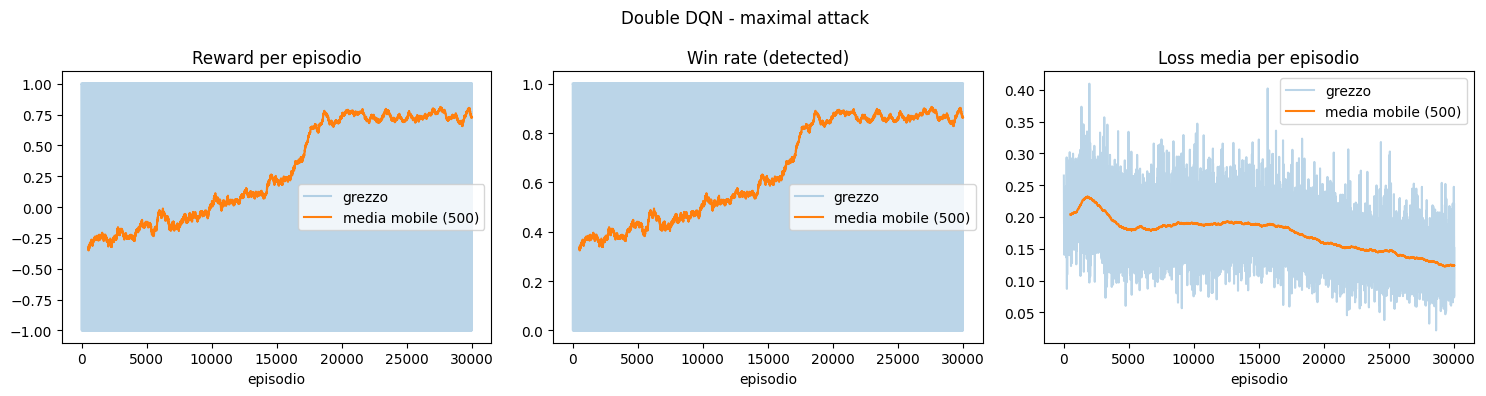

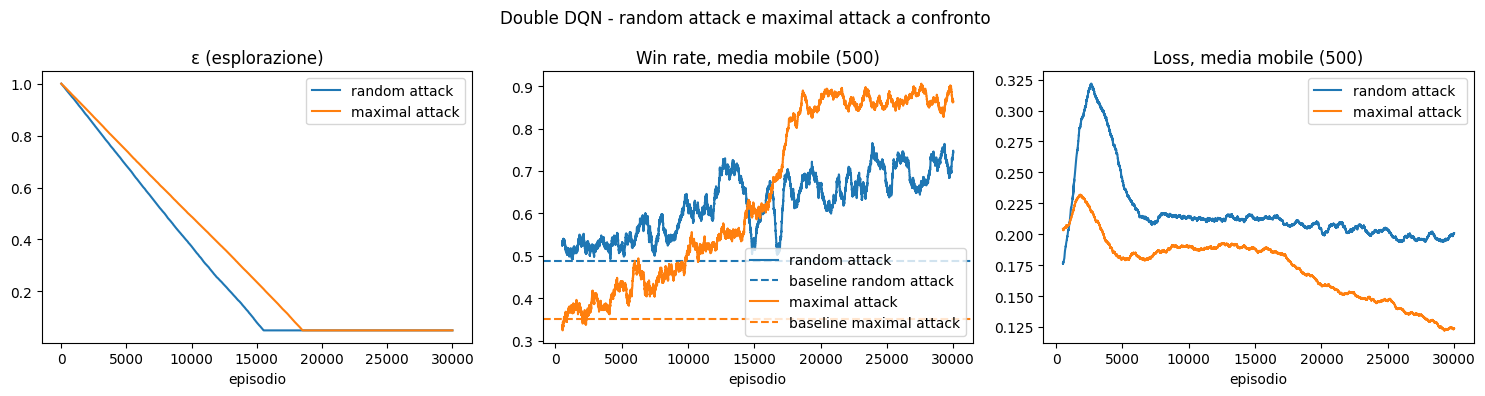

In [ ]:
plot_training({
  "Reward per episodio": storia_ddqn_maximal["reward"],
  "Win rate (detected)": storia_ddqn_maximal["detected"],
  "Loss media per episodio": storia_ddqn_maximal["loss"],
}, window=500, title="Double DQN - maximal attack")

# I due scenari a confronto (stesso colore per curva e baseline di uno scenario)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for (nome, storia), colore in zip([("random attack", storia_ddqn_random),
                                   ("maximal attack", storia_ddqn_maximal)], ["C0", "C1"]):
  axes[0].plot(storia["epsilon"], color=colore, label=nome)
  for ax, chiave in [(axes[1], "detected"), (axes[2], "loss")]:
    ma = moving_average(storia[chiave], 500)
    ax.plot(np.arange(499, len(storia[chiave])), ma, color=colore, label=nome)
  axes[1].axhline(results[("Baseline casuale", nome)]["detected"], color=colore,
                  linestyle="--", label=f"baseline {nome}")
titoli = ["ε (esplorazione)", "Win rate, media mobile (500)", "Loss, media mobile (500)"]
for ax, titolo in zip(axes, titoli):
  ax.set_title(titolo)
  ax.set_xlabel("episodio")
  ax.legend()
fig.suptitle("Double DQN - random attack e maximal attack a confronto")
plt.tight_layout()
plt.show()

Notiamo che:
- **ε e durata:** con episodi più corti ε arriva a 0.05 intorno all'episodio 18.400, contro circa 15.500 nel random attack (all'episodio 15.000 vale ancora 0.236).
- **Win rate:** nei blocchi da 5.000 episodi vale 38.3%, 45.3%, 55.1%, 76.4%, 86.8% e **86.9%**. All'inizio la media mobile è vicina alla baseline (35.1%) e sale piano finché ε è alto. Il salto più grande arriva tra gli episodi 15.500 e 18.500 circa, mentre ε finisce di scendere: la media mobile passa da circa 0.6 a circa 0.85. Negli ultimi 10.000 episodi resta tra circa 0.83 e 0.90, senza crolli come quello del random attack.
- **Confronto tra scenari:** il maximal attack parte più in basso, perché la sua baseline è più bassa, ma dall'episodio 17.000 circa la sua curva supera quella del random attack e resta sopra fino alla fine. Negli ultimi 5.000 episodi il DDQN sta sopra la baseline nel maximal attack (86.9% contro 35.1%) e nel random attack (70.9% contro 48.9%).
- **Loss:** il picco della media mobile è più basso (circa 0.23 intorno all'episodio 2.000, contro 0.32).

Valutiamo la policy **greedy** (ε = 0) come per il random attack: stessa `evaluate_policy`, stesso numero di episodi (`N_EVAL`), azioni più scelte e quota di passi sullo START.

In [ ]:
# Policy greedy (ε = 0) dell'agente addestrato sul maximal attack
azioni_ddqn_maximal = Counter()

def policy_ddqn_maximal(obs):
  azione = agent_ddqn_maximal.select_action(obs, 0.0)
  azioni_ddqn_maximal[azione] += 1
  return azione


res = evaluate_policy(env_ddqn_maximal, policy_ddqn_maximal, n_episodes=N_EVAL)
results[("DDQN", "maximal attack")] = res

print_eval("Baseline casuale - maximal attack", results[("Baseline casuale", "maximal attack")])
print_eval("DDQN greedy - maximal attack", res)

passi_ddqn_maximal = sum(azioni_ddqn_maximal.values())
print("\nAzioni più scelte dalla policy greedy (nodo = azione // 5, tipo = azione % 5, 4 = rilevamento):")
for azione, n in azioni_ddqn_maximal.most_common(5):
  print(f"  azione {azione:2d} (nodo {azione // 5}, tipo {azione % 5}): {n / passi_ddqn_maximal:.1%}")

print(f"\nQuota di passi sullo START (azioni 15-19): DDQN random attack {quota_start(azioni_ddqn):.1%}, "
      f"DDQN maximal attack {quota_start(azioni_ddqn_maximal):.1%}")

Baseline casuale - maximal attack detected= 35.1%  hacked= 64.8%  timeout=  0.0%  reward=-0.297 ± 0.955  durata media=4.1
DDQN greedy - maximal attack     detected= 92.2%  hacked=  7.8%  timeout=  0.0%  reward=+0.843 ± 0.538  durata media=4.6

Azioni più scelte dalla policy greedy (nodo = azione // 5, tipo = azione % 5, 4 = rilevamento):
  azione  0 (nodo 0, tipo 0): 45.9%
  azione  4 (nodo 0, tipo 4): 40.3%
  azione  1 (nodo 0, tipo 1): 13.8%

Quota di passi sullo START (azioni 15-19): DDQN random attack 0.0%, DDQN maximal attack 0.0%


Notiamo che:
- **Confronto con la baseline:** la policy greedy rileva l'attaccante nel **92.2%** degli episodi contro il 35.1% della baseline casuale, con reward media **+0.843** contro -0.297.
- **Durata:** 4.6 passi in media, contro i 4.1 della baseline.
- **Strategia appresa:** la policy usa solo **tre azioni**, tutte sul nodo dati: difesa di tipo 0 (azione 0, 45.9% dei passi), rilevamento (azione 4, 40.3%) e difesa di tipo 1 (azione 1, 13.8%). Non difende mai i server né lo START (0.0% dei passi sullo START).

## Confronto finale e conclusioni

Prima del riepilogo facciamo una valutazione incrociata tra il DDQN addestrato sul random attack contro il maximal attack e il DDQN addestrato sul maximal attack contro il random attack. Nessun agente viene riaddestrato, si tratta della stessa policy greedy messa davanti a un attaccante che non ha mai incontrato in training così misuriamo quanto è robusta la strategia appresa.

In [ ]:
# Valutazione incrociata
agenti_ddqn = {"random attack": agent_ddqn_random, "maximal attack": agent_ddqn_maximal}

for nome_train, agent in agenti_ddqn.items():
  for nome_eval, env_cls in SCENARI.items():
    if nome_eval != nome_train:
      env = DefenderWrapper(env_cls(), reward_mode="outcome")
      res = evaluate_policy(env, lambda obs: agent.select_action(obs, 0.0), n_episodes=N_EVAL)
      results[("DDQN incrociato", nome_eval)] = res

print("Win rate (detected) della policy greedy\n")
print(f"{'addestrato su / valutato su':<30}{'random attack':>16}{'maximal attack':>16}")
for nome_train in agenti_ddqn:
  riga = [results[("DDQN" if nome_eval == nome_train else "DDQN incrociato", nome_eval)]["detected"]
          for nome_eval in SCENARI]
  print(f"{nome_train:<30}" + "".join(f"{p:>16.1%}" for p in riga))

Win rate (detected) della policy greedy

addestrato su / valutato su      random attack  maximal attack
random attack                            75.1%           63.0%
maximal attack                           71.7%           92.2%


Ora la tabella riepilogativa con tutte le valutazioni greedy e il grafico a barre del win rate. Tutte le valutazioni usano la solita funzione `evaluate_policy` con `N_EVAL` episodi.

Baseline casuale - random attack detected= 48.9%  hacked= 51.1%  timeout=  0.0%  reward=-0.023 ± 1.000  durata media=5.0
SARSA - random attack            detected= 60.2%  hacked= 39.9%  timeout=  0.0%  reward=+0.203 ± 0.979  durata media=4.6
DDQN - random attack             detected= 75.1%  hacked= 24.9%  timeout=  0.0%  reward=+0.502 ± 0.865  durata media=4.3
DDQN incrociato - random attack  detected= 71.7%  hacked= 28.3%  timeout=  0.0%  reward=+0.433 ± 0.901  durata media=4.4

Baseline casuale - maximal attack detected= 35.1%  hacked= 64.8%  timeout=  0.0%  reward=-0.297 ± 0.955  durata media=4.1
DDQN - maximal attack            detected= 92.2%  hacked=  7.8%  timeout=  0.0%  reward=+0.843 ± 0.538  durata media=4.6
DDQN incrociato - maximal attack detected= 63.0%  hacked= 37.0%  timeout=  0.0%  reward=+0.261 ± 0.965  durata media=3.9



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


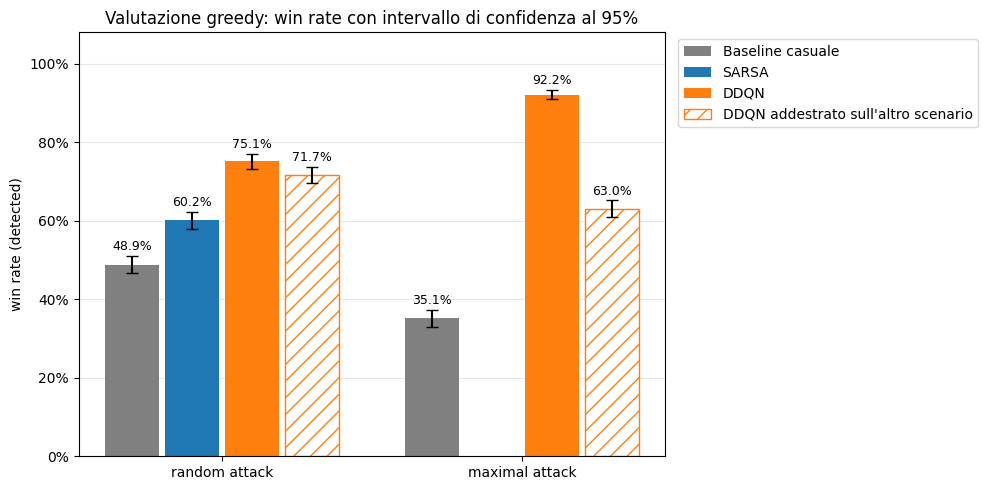

In [ ]:
# Serie del grafico: stesso colore per lo stesso agente, tratteggio per il DDQN valutato sull'altro scenario
SERIE = {
  "Baseline casuale": dict(color="gray"),
  "SARSA": dict(color="C0"),
  "DDQN": dict(color="C1"),
  "DDQN incrociato": dict(facecolor="white", edgecolor="C1", hatch="//")
}
ETICHETTE = {"DDQN incrociato": "DDQN addestrato sull'altro scenario"}
nomi_scenari = list(SCENARI)

# Tabella riepilogativa
for scenario in nomi_scenari:
  for serie in SERIE:
    if (serie, scenario) in results:
      print_eval(f"{serie} - {scenario}", results[(serie, scenario)])
  print()

# Grafico a barre del win rate con IC 95%
larghezza = 0.2
fig, ax = plt.subplots(figsize=(10, 5))
for i, (serie, stile) in enumerate(SERIE.items()):
  pos = [j for j, scenario in enumerate(nomi_scenari) if (serie, scenario) in results]
  p = np.array([results[(serie, nomi_scenari[j])]["detected"] for j in pos])
  ic = 1.96 * np.sqrt(p * (1 - p) / N_EVAL)
  barre = ax.bar(np.array(pos) + (i - 1.5) * larghezza, p, larghezza * 0.9, yerr=ic, capsize=4,
                 label=ETICHETTE.get(serie, serie), **stile)
  ax.bar_label(barre, labels=[f"{v:.1%}" for v in p], padding=2, fontsize=9)

ax.set_xticks(np.arange(len(nomi_scenari)))
ax.set_xticklabels(nomi_scenari)
ax.set_ylim(0, 1.08)
ax.set_yticks(np.linspace(0, 1, 6))
ax.set_yticklabels([f"{v:.0%}" for v in np.linspace(0, 1, 6)])
ax.set_ylabel("win rate (detected)")
ax.set_title("Valutazione greedy: win rate con intervallo di confidenza al 95%")
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Notiamo che:
- **Tutti gli agenti battono la baseline**.
- **SARSA e DDQN:** nel random attack, a parità di episodi, DDQN supera SARSA.
- **Valutazione incrociata:**
  - il DDQN addestrato sul maximal attack, valutato sul random attack, rileva l'attaccante nel 71.7% degli episodi, ovvero solo 3.4 punti sotto il DDQN addestrato su quello scenario e 11.5 punti sopra SARSA;
  - il DDQN addestrato sul random attack, valutato sul maximal attack, arriva al 63.0%, ovvero 29.2 punti sotto il DDQN specializzato (92.2%), ma 27.9 punti sopra la baseline.

In sintesi:
- **Gli agenti RL chiaramente difendono meglio di un difensore casuale**.
- **Il Double DQN supera SARSA** grazie alla generalizzazione della rete.